In [1]:
from ultralytics import YOLO
import os
import matplotlib.pyplot as plt
import gc
import torch
import os
import sys
sys.path.insert(0, os.path.abspath(os.path.join("..")))
from pipeline.preprocessing import BackgroundEraser
import glob
from pipeline.feature_learning.vae import VAE
from PIL import Image
from torchvision import transforms
from pipeline.feature_learning.vae import resize_with_padding
from pipeline.preprocessing import Repair
from pipeline.preprocessing import Normalizer

# PIPELINE

## Preprocessing

### Shard selection and  background cleaning

In [ ]:

#image_paths = glob.glob("/caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/2012_Survey Gladiatorenschule/**/*.jpg", recursive=True)
image_path= "/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256/Rims_256/**/*.jpg"

print(f"Found {len(image_path)} images.")
 
br=BackgroundEraser(input_path=image_path, batch_size=32, num_workers=16)

erased=br.run()

Found 0 images.
Output path for step BackgroundEraser : ../data/pipeline/default_run/PreprocessingStep/BackgroundEraser
_detectshards


Detecting shards: 0image [00:00, ?image/s]


FileNotFoundError: No images or videos found in /tmp/yolo_batch_fwfxcdzw. Supported formats are:
images: {'avif', 'jpeg', 'jpg', 'png', 'heif', 'dng', 'tiff', 'tif', 'mpo', 'bmp', 'heic', 'jp2', 'webp'}
videos: {'webm', 'm4v', 'ts', 'mov', 'wmv', 'gif', 'mkv', 'mpg', 'asf', 'mpeg', 'avi', 'mp4'}

### Resize & Crop

In [4]:
crop_step = Normalizer(input_path=image_paths, background_color=(0, 0, 0))

cropped= crop_step.run()

Output path for step Normalizer : ../data/pipeline/default_run/PreprocessingStep/Normalizer


FileNotFoundError: No existing images with extensions ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp') found under []

### Enhancing Picture Quality

In [4]:
repair_step = Repair(
    input_path=erased,
    max_distance=20,
    output_thickness=3,   # ← ez az új paraméter
)

result_path = repair_step.run()

Output path for step Repair : ../data/pipeline/default_run/PreprocessingStep/Repair


Repairing images:   0%|          | 0/13 [00:00<?, ?image/s]

Repairing images: 100%|██████████| 13/13 [00:00<00:00, 17.12image/s]


## Feature Learning

In [8]:
vae = VAE(f=4, n=3, s=1, k=128)  # k=128 latent dimension
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae.to(device)

vae.train_model(
    folder="/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot", 
    epochs=1000, 
    lr=1e-5,      
    batch_size=128
)

# latent_vectors = vae.extract_features(
#     folder="/caa/Homes01/alaczko/Diploma/Diploma/data/processed/cleared_images",
#     batch_size=32
# )

# print(latent_vectors.shape)

torch.save(vae.state_dict(), "../models/feature_learning/roco.pt")

Dataset size: 574
[epoch 1] loss: 5101956.900 | beta: 0.000
[epoch 2] loss: 5098701.550 | beta: 0.020
[epoch 3] loss: 5095421.700 | beta: 0.040
[epoch 4] loss: 5092196.250 | beta: 0.060
[epoch 5] loss: 5089047.950 | beta: 0.080
[epoch 6] loss: 5085803.400 | beta: 0.100
[epoch 7] loss: 5082410.350 | beta: 0.120
[epoch 8] loss: 5078804.100 | beta: 0.140
[epoch 9] loss: 5075115.750 | beta: 0.160
[epoch 10] loss: 5070875.350 | beta: 0.180
[epoch 11] loss: 5065973.700 | beta: 0.200
[epoch 12] loss: 5059455.950 | beta: 0.220
[epoch 13] loss: 5050523.950 | beta: 0.240
[epoch 14] loss: 5037483.600 | beta: 0.260
[epoch 15] loss: 5018464.500 | beta: 0.280
[epoch 16] loss: 4991647.450 | beta: 0.300
[epoch 17] loss: 4955434.950 | beta: 0.320
[epoch 18] loss: 4909614.850 | beta: 0.340
[epoch 19] loss: 4853415.900 | beta: 0.360
[epoch 20] loss: 4784805.100 | beta: 0.380
[epoch 21] loss: 4704248.700 | beta: 0.400
[epoch 22] loss: 4605796.200 | beta: 0.420
[epoch 23] loss: 4489274.000 | beta: 0.440
[e

[epoch 1] loss: 1353931.506
[epoch 2] loss: 1353410.569
[epoch 3] loss: 1352911.637
[epoch 4] loss: 1352423.925
[epoch 5] loss: 1351923.169
[epoch 6] loss: 1351422.119
[epoch 7] loss: 1350913.719
[epoch 8] loss: 1350395.262
[epoch 9] loss: 1349917.094
[epoch 10] loss: 1349405.206
torch.Size([304, 256])

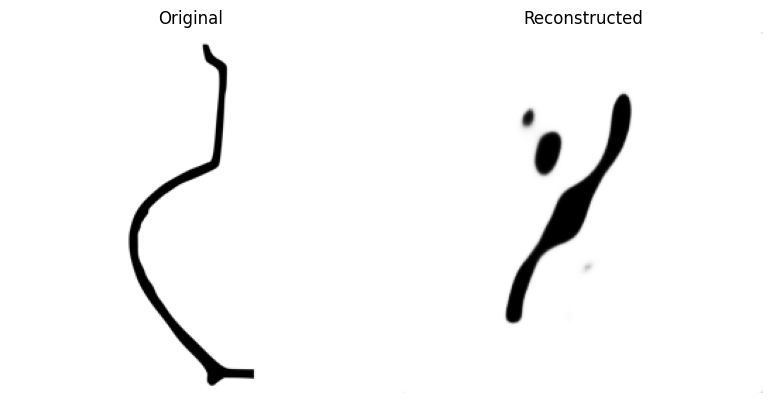

In [11]:
vae_eval=VAE(f=4, n=3, s=1, k=128)

vae_eval.load_state_dict(torch.load("/caa/Homes01/alaczko/Diploma/Diploma/models/feature_learning/vae_parisotto_small.pt", map_location="cuda"))
vae_eval.eval()

#making sure the formula is correct
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Lambda(lambda img: resize_with_padding(img, 256)),
    transforms.ToTensor(),
])

img_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot/BERT11-60b.png"
original_img = Image.open(img_path)
input_tensor = transform(original_img).unsqueeze(0) #adding batch dim

with torch.no_grad():
    reconstructed, mu, sigma = vae_eval(input_tensor)

orig_np = input_tensor.squeeze().numpy()
recon_np = reconstructed.squeeze().numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(recon_np, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Reconstructed")
axes[1].axis('off')

plt.tight_layout()
plt.show()